# 12 — Clean spark spread and CCGT dispatch

What is a forecast worth in euros? A hypothetical 1 MW gas plant (CCGT, 55% efficiency) decides each day at 12:00 which hours to run tomorrow.

- **Input:** dataset (05), gas (04), EUA (11), test forecasts (10)
- **Output:** `data/processed/spark_spread_hourly_2021_2025q3.parquet`, `data/processed/dispatch_test_hourly_2024q4_2025q3.parquet`, `results/12_*`
- **Part A — spark spread:** clean spark spread = power price − heat rate × gas − emission factor × CO₂. The market-implied heat rate stays at 2.2–2.3 while gas moves 13×: gas is marginal and the value shifts to evening hours, as solar pushes midday below the cost of a CCGT.
- **Part B — dispatch:** exact unit commitment with **dynamic programming** (start-up cost, minimum run time, state carried over midnight).

| Forecast | Capture rate | k€/MW/year |
|---|---|---|
| perfect foresight | 100% | 95.1 |
| ensemble · LEAR | 92.4% · 92.3% | 87.8 · 87.8 |
| XGBoost · linear | 91.5% · 90.9% | 87.0 · 86.4 |
| naive | 82.6% | 78.6 |

- **Conclusion:** forecasting is worth ≈ +9 k€/MW/year over the naive; differences between ML models are below what one year can detect (Newey-West HAC test).

In [1]:
# --- 12_spark_spread - cell 1: plant parameters ---------------------------------------
# A HYPOTHETICAL gas-fired CCGT, normalised to 1 MW of capacity: results come out in
# €/MWh and €/MW-year, with no need to guess the size of a real plant.
# Every number below is an assumption: it lives here, once, with its reason.
%load_ext autoreload
%autoreload 2

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import forecasting as fc

# --- Physics of the fuel ---------------------------------------------------------------
# Gas prices (GME MGP-GAS) are quoted on the GROSS calorific value (GCV / PCS), while
# plant efficiencies and IPCC emission factors are on the NET calorific value (LHV / PCI).
# Mixing the two bases silently shifts one cost term by ~10%.
GCV_OVER_LHV = 1.108                        # natural gas, typical ratio

# IPCC default for natural gas: 56.1 tCO2/TJ (LHV basis); 1 MWh = 0.0036 TJ
EMISSION_FACTOR_GAS_LHV = 56.1 * 0.0036     # ≈ 0.202 tCO2 per MWh_th (LHV)

# --- The plant ---------------------------------------------------------------------------
EFFICIENCY_LHV = 0.55                       # modern CCGT at full load
EFFICIENCY_LHV_SENSITIVITY = [0.50, 0.55, 0.58]   # older unit / base case / best in class


def plant_coefficients(efficiency_lhv):
    """Turn one efficiency (LHV basis) into the two coefficients of the spread formula,
    each on the basis its price is quoted in:
      heat_rate_gcv     [MWh_th(GCV) / MWh_el] -> multiplies the GME gas price
      emission_factor_el [tCO2 / MWh_el]        -> multiplies the EUA price
    The CO2 per MWh_el is physical: it is the same on any basis, as long as the
    emission factor and the efficiency share one (here both LHV)."""
    efficiency_gcv = efficiency_lhv / GCV_OVER_LHV
    heat_rate_gcv = 1.0 / efficiency_gcv
    emission_factor_el = EMISSION_FACTOR_GAS_LHV / efficiency_lhv
    return heat_rate_gcv, emission_factor_el


HEAT_RATE_GCV, EMISSION_FACTOR_EL = plant_coefficients(EFFICIENCY_LHV)

# --- Costs used only in Part B (dispatch) -------------------------------------------------
# Variable O&M: wear and consumables per MWh produced, on top of fuel and CO2.
VOM_EUR_MWH = 3.0
# Hot start cost per MW of capacity (extra fuel + wear). Order of magnitude from the
# cycling-cost literature (NREL, Kumar et al. 2012); it goes into the sensitivity too.
START_COST_EUR_PER_MW = 50.0
# Minimum up time: once started, the unit runs at least this many consecutive hours.
MIN_RUN_HOURS = 4

# --- Sanity checks: fail loudly if a typo moves a parameter out of physical range ---------
assert 1.8 < HEAT_RATE_GCV < 2.2, HEAT_RATE_GCV
assert 0.33 < EMISSION_FACTOR_EL < 0.42, EMISSION_FACTOR_EL

print(f"efficiency LHV / GCV   : {EFFICIENCY_LHV:.3f} / {EFFICIENCY_LHV / GCV_OVER_LHV:.3f}")
print(f"heat rate (GCV basis)  : {HEAT_RATE_GCV:.4f} MWh_th / MWh_el")
print(f"emission factor el.    : {EMISSION_FACTOR_EL:.4f} tCO2 / MWh_el\n")

# Worked example from the discussion: power 110, gas 35 €/MWh, EUA 70 €/t
example_power, example_gas, example_eua = 110.0, 35.0, 70.0
example_dirty = example_power - HEAT_RATE_GCV * example_gas
example_clean = example_dirty - EMISSION_FACTOR_EL * example_eua
print(f"example: dirty {example_dirty:.2f}  clean {example_clean:.2f}  "
      f"clean - VOM {example_clean - VOM_EUR_MWH:.2f} €/MWh\n")

# Sensitivity table: how much the two coefficients move with the efficiency
sensitivity = pd.DataFrame(
    [(eff, *plant_coefficients(eff)) for eff in EFFICIENCY_LHV_SENSITIVITY],
    columns=["efficiency_lhv", "heat_rate_gcv", "emission_factor_el"],
)
print(sensitivity.round(4).to_string(index=False))

# --- Persist the assumptions next to the results, like 08/09/10 ---------------------------
config = {
    "plant": "hypothetical CCGT, normalised to 1 MW",
    "gcv_over_lhv": GCV_OVER_LHV,
    "emission_factor_gas_lhv_t_per_mwh_th": EMISSION_FACTOR_GAS_LHV,
    "efficiency_lhv": EFFICIENCY_LHV,
    "efficiency_lhv_sensitivity": EFFICIENCY_LHV_SENSITIVITY,
    "heat_rate_gcv": HEAT_RATE_GCV,
    "emission_factor_el_t_per_mwh_el": EMISSION_FACTOR_EL,
    "vom_eur_mwh": VOM_EUR_MWH,
    "start_cost_eur_per_mw": START_COST_EUR_PER_MW,
    "min_run_hours": MIN_RUN_HOURS,
}
config_path = fc.RESULTS / "12_spark_spread_config.json"
config_path.write_text(json.dumps(config, indent=2))
print(f"\nsaved -> {config_path.name}")

efficiency LHV / GCV   : 0.550 / 0.496
heat rate (GCV basis)  : 2.0145 MWh_th / MWh_el
emission factor el.    : 0.3672 tCO2 / MWh_el

example: dirty 39.49  clean 13.79  clean - VOM 10.79 €/MWh

 efficiency_lhv  heat_rate_gcv  emission_factor_el
           0.50         2.2160              0.4039
           0.55         2.0145              0.3672
           0.58         1.9103              0.3482

saved -> 12_spark_spread_config.json


In [2]:
# --- 12_spark_spread - cell 2: hourly join of power, gas and EUA prices --------------
# Two DIFFERENT price sets per hour, never to be mixed:
#   decision   -> what was known at 12:00 of D-1 (Part B: whether to start the plant)
#   settlement -> what the plant actually earned and paid (Part A, realised margin)
dataset = pd.read_parquet(fc.PROCESSED / "dataset_hourly_2021_2025q3.parquet")
gas = pd.read_parquet(fc.PROCESSED / "gas_mgp_daily_2020_2025.parquet")
eua = pd.read_parquet(fc.PROCESSED / "eua_auction_daily_2020_2025.parquet")

hourly = dataset[["ts_utc", "ts_local", "national_price", "gas_price_d1_eur_mwh"]].copy()

# Wall-clock time in Rome, without timezone. All calendar arithmetic below is done
# on this: subtracting hours from a tz-aware timestamp works in ABSOLUTE time and
# lands on the wrong side of midnight on DST days.
wall_clock = hourly["ts_local"].dt.tz_localize(None)

hourly["delivery_date"] = wall_clock.dt.normalize()
decision_date = hourly["delivery_date"] - pd.Timedelta(days=1)

# Physical gas day: 06:00 -> 06:00. Hours 00-05 of D burn gas of gas day D-1.
GAS_DAY_START_HOUR = 6
hourly["gas_day_physical"] = (
    wall_clock - pd.Timedelta(hours=GAS_DAY_START_HOUR)
).dt.normalize()

# Lookup series: one value per day (reindex needs a unique index)
gas_price = gas.set_index("gas_day")["price_eur_mwh"]
eua_price = eua.set_index("date")["eua_price_eur_t"]
eua_age = eua.set_index("date")["eua_age_days"]
assert gas_price.index.is_unique and eua_price.index.is_unique

# --- Decision prices (known at 12:00 of D-1) -------------------------------------------
# Gas D-1 is already in the dataset: rebuild it independently and demand equality,
# so the two notebooks cannot silently disagree on the timing rule.
rebuilt_gas_d1 = gas_price.reindex(decision_date).to_numpy()
assert (rebuilt_gas_d1 == hourly["gas_price_d1_eur_mwh"].to_numpy()).all()

hourly["eua_price_d1_eur_t"] = eua_price.reindex(decision_date).to_numpy()
hourly["eua_age_d1_days"] = eua_age.reindex(decision_date).to_numpy()

# --- Settlement prices (what actually happened) ------------------------------------------
hourly["gas_price_physical_eur_mwh"] = gas_price.reindex(hourly["gas_day_physical"]).to_numpy()
hourly["eua_price_d0_eur_t"] = eua_price.reindex(hourly["delivery_date"]).to_numpy()

# --- Blocking checks ------------------------------------------------------------------
assert len(hourly) == 41615, len(hourly)
assert hourly.notna().all().all(), hourly.isna().sum()

# Hours 00-05 must map to the previous gas day, hours 06-23 to the same day.
before_six = wall_clock.dt.hour < GAS_DAY_START_HOUR
expected_gas_day = hourly["delivery_date"] - pd.to_timedelta(before_six.astype(int), unit="D")
assert hourly["gas_day_physical"].eq(expected_gas_day).all()

# Every full gas day has 24 hours, 23 or 25 on DST weekends. The first (2020-12-31,
# only 00-05 of 1 Jan) and the last (2025-09-30, from 06:00 only) are partial.
hours_per_gas_day = hourly.groupby("gas_day_physical").size()
assert hours_per_gas_day.iloc[1:-1].isin([23, 24, 25]).all()
print("hours per gas day (full days only):")
print(hours_per_gas_day.iloc[1:-1].value_counts().sort_index().to_string(), "\n")

# --- How much does deciding with yesterday's gas cost? -----------------------------------
# Gap between the gas price of delivery day D and the D-1 price used to decide:
# the part of the fuel cost a bidder could NOT know at 12:00 of D-1.
daily_gas = hourly.groupby("delivery_date")["gas_price_d1_eur_mwh"].first().to_frame()
daily_gas["gas_price_d0"] = gas_price.reindex(daily_gas.index).to_numpy()
gas_gap = daily_gas["gas_price_d0"] - daily_gas["gas_price_d1_eur_mwh"]

gap_by_year = pd.DataFrame({
    "mean_gap_gas": gas_gap.groupby(gas_gap.index.year).mean(),
    "mae_gap_gas": gas_gap.abs().groupby(gas_gap.index.year).mean(),
})
# Same gap expressed in €/MWh of electricity, through the heat rate
gap_by_year["mae_gap_spread"] = gap_by_year["mae_gap_gas"] * HEAT_RATE_GCV
print("gas D vs D-1, €/MWh (last column: in €/MWh of spread):")
print(gap_by_year.round(2).to_string())

hours per gas day (full days only):
23       5
24    1724
25       4 

gas D vs D-1, €/MWh (last column: in €/MWh of spread):
               mean_gap_gas  mae_gap_gas  mae_gap_spread
delivery_date                                           
2021                   0.17         2.10            4.23
2022                  -0.02         7.04           14.18
2023                  -0.11         1.75            3.53
2024                   0.05         0.74            1.50
2025                  -0.06         0.88            1.77


In [3]:
# --- 12_spark_spread - cell 3: hourly dirty / clean spreads on settlement prices ------
# Settlement prices only: this is Part A, what a 1 MW CCGT would have earned.
hourly["fuel_cost_eur_mwh"] = HEAT_RATE_GCV * hourly["gas_price_physical_eur_mwh"]
hourly["co2_cost_eur_mwh"] = EMISSION_FACTOR_EL * hourly["eua_price_d0_eur_t"]

hourly["dirty_spread"] = hourly["national_price"] - hourly["fuel_cost_eur_mwh"]
hourly["clean_spread"] = hourly["dirty_spread"] - hourly["co2_cost_eur_mwh"]

# Market implied heat rate: how many MWh of gas one MWh of power "buys".
# Above HEAT_RATE_GCV <=> dirty spread > 0 for our plant.
assert (hourly["gas_price_physical_eur_mwh"] > 0).all()
hourly["implied_heat_rate"] = hourly["national_price"] / hourly["gas_price_physical_eur_mwh"]

# Hourly-option margin: run whenever clean spread beats VOM, earn nothing otherwise.
# 1 MW for 1 hour = 1 MWh, so summing over hours gives €/MW. UPPER BOUND: it ignores
# start costs and minimum up time, which Part B puts back.
hourly["option_margin_eur"] = (hourly["clean_spread"] - VOM_EUR_MWH).clip(lower=0)

# --- Per-year summary -------------------------------------------------------------------
# Calendar years; 2025 covers January-September only (end of the perimeter).
year = hourly["delivery_date"].dt.year
by_year = hourly.groupby(year)

summary = pd.DataFrame({
    "hours": by_year.size(),
    "power": by_year["national_price"].mean(),
    "fuel_cost": by_year["fuel_cost_eur_mwh"].mean(),
    "co2_cost": by_year["co2_cost_eur_mwh"].mean(),
    "dirty": by_year["dirty_spread"].mean(),
    "clean": by_year["clean_spread"].mean(),
    # Share of hours in the money, before and after variable O&M
    "pct_clean_pos": by_year["clean_spread"].apply(lambda s: (s > 0).mean() * 100),
    "pct_above_vom": by_year["clean_spread"].apply(lambda s: (s > VOM_EUR_MWH).mean() * 100),
    # Median, not mean: the ratio explodes in the few hours with very high power prices
    "median_implied_hr": by_year["implied_heat_rate"].median(),
    "option_margin_k_eur_mw": by_year["option_margin_eur"].sum() / 1000,
})
summary.index.name = "year"

# Accounting identity: power - fuel - co2 must equal clean spread, year by year
assert np.allclose(summary["power"] - summary["fuel_cost"] - summary["co2_cost"], summary["clean"])

print("€/MWh unless stated; option margin in k€ per MW per year (upper bound)\n")
print(summary.round(2).to_string(), "\n")

print("hourly distribution over the whole perimeter:")
print(hourly[["dirty_spread", "clean_spread", "implied_heat_rate"]].describe().round(2).to_string())

€/MWh unless stated; option margin in k€ per MW per year (upper bound)

      hours   power  fuel_cost  co2_cost  dirty  clean  pct_clean_pos  pct_above_vom  median_implied_hr  option_margin_k_eur_mw
year                                                                                                                           
2021   8760  125.46      93.19     19.41  32.27  12.87          73.65          66.58               2.82                  121.76
2022   8760  303.95     249.42     29.51  54.54  25.03          66.63          63.47               2.43                  289.42
2023   8760  127.24      84.89     30.58  42.34  11.76          74.42          68.23               3.03                  125.32
2024   8784  108.52      73.21     23.82  35.32  11.49          73.75          67.19               2.95                  115.51
2025   6551  116.42      82.21     26.15  34.21   8.06          70.80          64.72               2.91                   79.29 

hourly distribution over the w

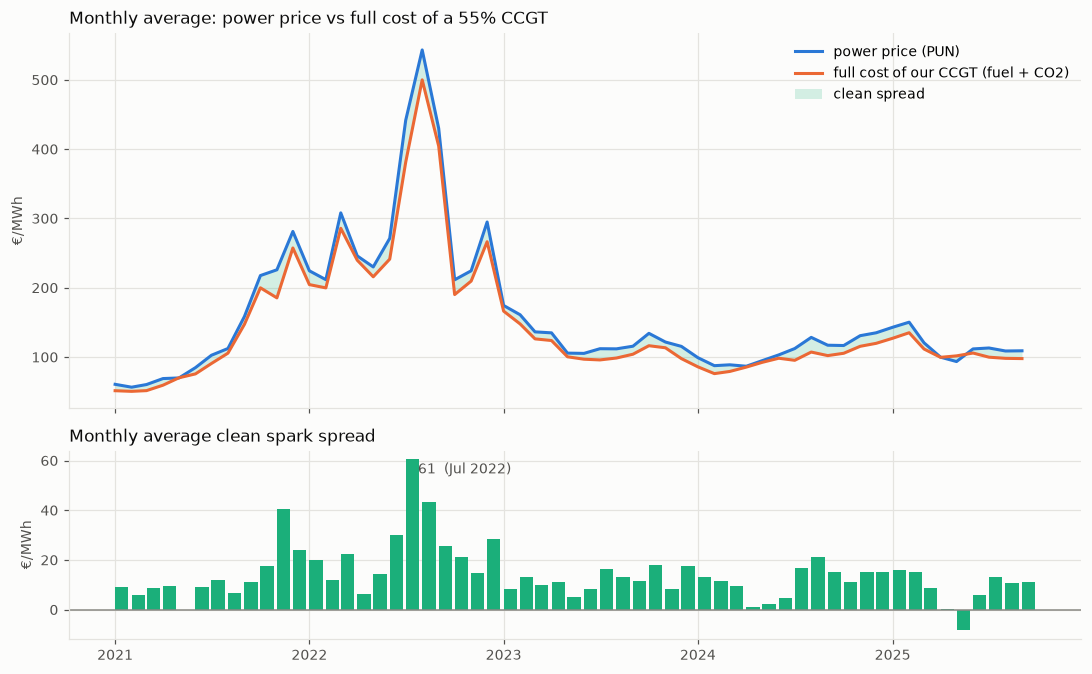

        power  full_cost  clean_spread  clean_implied_hr
count   57.00      57.00         57.00             57.00
mean   158.20     144.09         14.11              2.28
std     97.35      89.10         10.85              0.15
min     56.57      50.58         -8.18              1.80
25%    103.17      96.94          8.77              2.18
50%    117.13     105.86         11.85              2.27
75%    211.50     185.44         16.97              2.36
max    543.15     499.97         60.51              2.54 

months with negative average clean spread: ['2021-05', '2025-05']


In [4]:
# --- 12_spark_spread - cell 4: monthly view — power price vs full cost, clean spread ----
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# --- Plot style: defined once, reused by every figure of this notebook -------------------
COLOR_PRICE = "#2a78d6"    # power price          (categorical slot 1, blue)
COLOR_COST = "#eb6834"     # fuel + CO2 cost      (slot 2, orange)
COLOR_SPREAD = "#1baf7a"   # clean spark spread   (slot 3, aqua)
COLOR_TEXT = "#0b0b0b"
COLOR_TEXT_MUTED = "#52514e"
COLOR_GRID = "#e4e3df"
COLOR_REFERENCE = "#8a8984"  # reference lines (zero, our heat rate)

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": COLOR_GRID,
    "axes.labelcolor": COLOR_TEXT_MUTED,
    "axes.titlecolor": COLOR_TEXT,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,         # grid behind the data
    "grid.color": COLOR_GRID,
    "grid.linewidth": 0.8,
    "xtick.color": COLOR_TEXT_MUTED,
    "ytick.color": COLOR_TEXT_MUTED,
    "font.size": 9,
    "lines.linewidth": 2,
    "legend.frameon": False,
})

# --- Hourly: clean implied heat rate ------------------------------------------------------
# Power price net of the CO2 cost, per MWh of gas. Our plant is in the money exactly
# when this is above HEAT_RATE_GCV.
hourly["clean_implied_heat_rate"] = (
    (hourly["national_price"] - hourly["co2_cost_eur_mwh"])
    / hourly["gas_price_physical_eur_mwh"]
)

# --- Monthly aggregation --------------------------------------------------------------------
month = hourly["delivery_date"].dt.to_period("M").dt.to_timestamp()
monthly = hourly.groupby(month).agg(
    power=("national_price", "mean"),
    fuel_cost=("fuel_cost_eur_mwh", "mean"),
    co2_cost=("co2_cost_eur_mwh", "mean"),
    clean_spread=("clean_spread", "mean"),
    gas=("gas_price_physical_eur_mwh", "mean"),
)
monthly.index.name = "month"
monthly["full_cost"] = monthly["fuel_cost"] + monthly["co2_cost"]

# RATIO OF MEANS, not mean of hourly ratios: hourly ratios explode in price spikes,
# and only the ratio of means keeps the identity
#   clean spread = (clean implied heat rate - our heat rate) x gas price
monthly["clean_implied_hr"] = (monthly["power"] - monthly["co2_cost"]) / monthly["gas"]
assert np.allclose(
    monthly["clean_spread"],
    (monthly["clean_implied_hr"] - HEAT_RATE_GCV) * monthly["gas"],
)

# --- Figure 1: what the plant sells vs what it costs to run --------------------------------
fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, figsize=(10, 6.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

ax_top.plot(monthly.index, monthly["power"], color=COLOR_PRICE, label="power price (PUN)")
ax_top.plot(monthly.index, monthly["full_cost"], color=COLOR_COST,
            label="full cost of our CCGT (fuel + CO2)")
# The gap between the two lines IS the clean spread: shade it to make that visible
ax_top.fill_between(monthly.index, monthly["full_cost"], monthly["power"],
                    color=COLOR_SPREAD, alpha=0.18, linewidth=0, label="clean spread")
ax_top.set_ylabel("€/MWh")
ax_top.set_title("Monthly average: power price vs full cost of a 55% CCGT")
ax_top.legend(loc="upper right")

# One axis per panel (never two y-scales on one plot): the spread gets its own panel
ax_bottom.bar(monthly.index, monthly["clean_spread"], width=25, align="edge", color=COLOR_SPREAD)
ax_bottom.axhline(0, color=COLOR_REFERENCE, linewidth=1)
ax_bottom.set_ylabel("€/MWh")
ax_bottom.set_title("Monthly average clean spark spread")

# Selective direct label: only the extreme month, not every bar
peak = monthly["clean_spread"].idxmax()
ax_bottom.annotate(f"{monthly.loc[peak, 'clean_spread']:.0f}  ({peak:%b %Y})",
                   xy=(peak, monthly.loc[peak, "clean_spread"]),
                   xytext=(8, -2), textcoords="offset points",
                   color=COLOR_TEXT_MUTED, va="top")

ax_bottom.xaxis.set_major_locator(mdates.YearLocator())
ax_bottom.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
plt.show()

# The numbers behind the figure, for reading rather than eyeballing
print(monthly[["power", "full_cost", "clean_spread", "clean_implied_hr"]]
      .describe().round(2).to_string(), "\n")
print("months with negative average clean spread:",
      monthly.index[monthly["clean_spread"] < 0].strftime("%Y-%m").tolist())

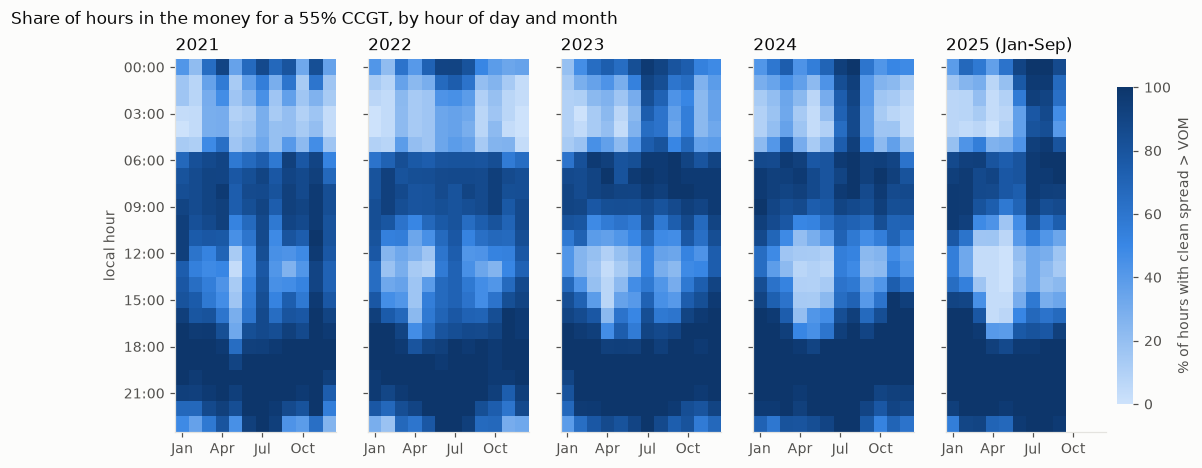

% of hours in the money, by year and time band:
local_hour  night 00-05  morning 06-10  midday 11-15  afternoon 16-17  evening 18-21  late 22-23
year                                                                                            
2021               29.6           82.8          61.9             80.8           97.3        72.7
2022               26.5           80.7          52.8             79.7           97.5        73.8
2023               42.1           86.5          46.1             79.7           98.7        84.0
2024               37.9           85.8          45.2             80.9           99.2        85.7
2025               45.8           82.6          29.5             68.5           99.3        91.9 

average clean spread at midday (11-15), €/MWh:
      Apr-Jun  other months
year                       
2021     -0.4          13.7
2022     -8.1          10.4
2023    -12.8          -0.8
2024    -22.0           2.5
2025    -36.6          -5.6


In [5]:
# --- 12_spark_spread - cell 5: when is the plant in the money? hour x month, per year ---
from matplotlib.colors import LinearSegmentedColormap

# Sequential ramp, one hue light -> dark (blue steps 100 -> 700): magnitude, not identity
SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)

# Local wall-clock hour and month: the hour a trader talks about ("the 20:00 peak")
hourly["local_hour"] = wall_clock.dt.hour
hourly["month_of_year"] = hourly["delivery_date"].dt.month
hourly["year"] = hourly["delivery_date"].dt.year

# In the money = clean spread above VOM: the hours a flexible plant would want to run
hourly["in_the_money"] = hourly["clean_spread"] > VOM_EUR_MWH

YEARS = sorted(hourly["year"].unique())
fig, axes = plt.subplots(1, len(YEARS), figsize=(13, 4.4), sharey=True)

for ax, year in zip(axes, YEARS):
    # Rows = hour of day, columns = month; missing months (Oct-Dec 2025) stay NaN
    grid = (
        hourly[hourly["year"] == year]
        .pivot_table(index="local_hour", columns="month_of_year",
                     values="in_the_money", aggfunc="mean")
        .reindex(index=range(24), columns=range(1, 13))
        * 100
    )
    image = ax.imshow(grid, aspect="auto", cmap=SEQUENTIAL_BLUE, vmin=0, vmax=100,
                      origin="upper", interpolation="nearest")
    ax.set_title(str(year) + (" (Jan-Sep)" if year == 2025 else ""))
    ax.set_xticks(range(0, 12, 3), ["Jan", "Apr", "Jul", "Oct"])
    ax.grid(False)                      # a grid on top of cells only adds noise

axes[0].set_yticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
axes[0].set_ylabel("local hour")

colorbar = fig.colorbar(image, ax=axes, shrink=0.85, pad=0.01)
colorbar.set_label("% of hours with clean spread > VOM")
colorbar.outline.set_visible(False)
fig.suptitle("Share of hours in the money for a 55% CCGT, by hour of day and month",
             x=0.01, ha="left", fontsize=11, color=COLOR_TEXT)
plt.show()

# --- The same information as numbers: time bands, per year ------------------------------
hour_band = pd.cut(hourly["local_hour"], bins=[-1, 5, 10, 15, 17, 21, 23],
                   labels=["night 00-05", "morning 06-10", "midday 11-15",
                           "afternoon 16-17", "evening 18-21", "late 22-23"])
share_by_band = (
    hourly.groupby(["year", hour_band], observed=True)["in_the_money"].mean()
    .unstack() * 100
)
print("% of hours in the money, by year and time band:")
print(share_by_band.round(1).to_string(), "\n")

# Spring (April-June) vs the rest, midday only: the hydro + solar hypothesis
is_midday = hour_band.eq("midday 11-15")
season = np.where(hourly["month_of_year"].isin([4, 5, 6]), "Apr-Jun", "other months")
midday_spread = (
    hourly[is_midday].groupby(["year", season[is_midday]])["clean_spread"].mean().unstack()
)
print("average clean spread at midday (11-15), €/MWh:")
print(midday_spread.round(1).to_string())

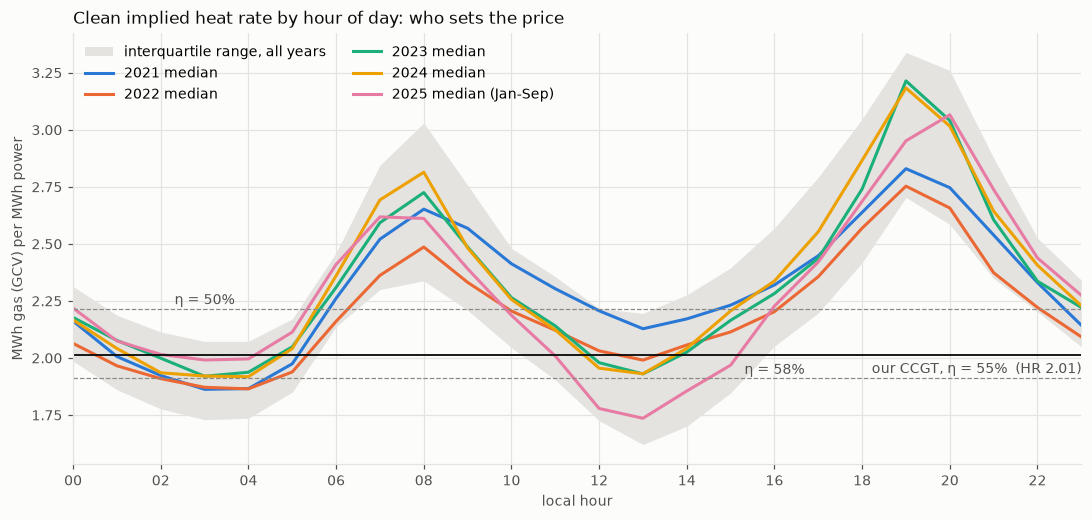

                 clean_implied_hr  clean_spread_median  implied_efficiency_lhv
local_hour                                                                    
night 00-05                 1.990               -1.176                   0.557
morning 06-10               2.408               17.359                   0.460
midday 11-15                2.058                2.132                   0.538
afternoon 16-17             2.357               15.050                   0.470
evening 18-21               2.786               34.625                   0.398
late 22-23                  2.271               11.070                   0.488 

saved 41615 rows x 17 cols -> spark_spread_hourly_2021_2025q3.parquet


In [6]:
# --- 12_spark_spread - cell 6: the merit-order signature through the day + save Part A ---
# Clean implied heat rate = efficiency of the unit that sets the price, read from prices
# alone. Our plant earns (clean spread > 0) whenever the curve is above our heat rate.
YEAR_COLORS = {            # categorical slots 1-5, fixed order: colour follows the year
    2021: "#2a78d6", 2022: "#eb6834", 2023: "#1baf7a", 2024: "#eda100", 2025: "#e87ba4",
}

by_hour_year = (
    hourly.groupby(["year", "local_hour"])["clean_implied_heat_rate"].median().unstack(0)
)
# Pooled interquartile range across all years: how wide the hour-to-hour spread is
pooled = hourly.groupby("local_hour")["clean_implied_heat_rate"]
iqr_low, iqr_high = pooled.quantile(0.25), pooled.quantile(0.75)

fig, ax = plt.subplots(figsize=(10, 4.8))

ax.fill_between(iqr_low.index, iqr_low, iqr_high, color=COLOR_GRID, linewidth=0,
                label="interquartile range, all years")
for year, color in YEAR_COLORS.items():
    ax.plot(by_hour_year.index, by_hour_year[year], color=color,
            label=f"{year} median" + (" (Jan-Sep)" if year == 2025 else ""))

# Reference: our plant, and the efficiency sensitivity around it
ax.axhline(HEAT_RATE_GCV, color=COLOR_TEXT, linewidth=1.2)
ax.annotate(f"our CCGT, η = {EFFICIENCY_LHV:.0%}  (HR {HEAT_RATE_GCV:.2f})",
            xy=(23, HEAT_RATE_GCV), xytext=(0, -12), textcoords="offset points",
            ha="right", color=COLOR_TEXT_MUTED)
# Label each sensitivity line at an hour where no curve crosses it (avoids collisions)
SENSITIVITY_LABEL_HOUR = {min(EFFICIENCY_LHV_SENSITIVITY): 3, max(EFFICIENCY_LHV_SENSITIVITY): 16}
for efficiency, label_hour in SENSITIVITY_LABEL_HOUR.items():
    heat_rate, _ = plant_coefficients(efficiency)
    ax.axhline(heat_rate, color=COLOR_REFERENCE, linewidth=0.8, linestyle="--")
    ax.annotate(f"η = {efficiency:.0%}", xy=(label_hour, heat_rate), xytext=(0, 3),
                textcoords="offset points", ha="center", color=COLOR_TEXT_MUTED)

ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlim(0, 23)
ax.set_xlabel("local hour")
ax.set_ylabel("MWh gas (GCV) per MWh power")
ax.set_title("Clean implied heat rate by hour of day: who sets the price")
ax.legend(loc="upper left", ncols=2)
fig.tight_layout()
plt.show()

# Numbers behind the figure: median implied HR and its implied efficiency, by time band
band_view = hourly.groupby(hour_band, observed=True).agg(
    clean_implied_hr=("clean_implied_heat_rate", "median"),
    clean_spread_median=("clean_spread", "median"),
)
# Efficiency of the marginal unit implied by the heat rate (LHV basis, like EFFICIENCY_LHV)
band_view["implied_efficiency_lhv"] = GCV_OVER_LHV / band_view["clean_implied_hr"]
print(band_view.round(3).to_string(), "\n")

# --- Save the hourly spreads: the input of Part B -------------------------------------------
SPREAD_COLUMNS = [
    "ts_utc", "ts_local", "delivery_date", "national_price",
    # decision prices (known at 12:00 of D-1)
    "gas_price_d1_eur_mwh", "eua_price_d1_eur_t", "eua_age_d1_days",
    # settlement prices and spreads
    "gas_day_physical", "gas_price_physical_eur_mwh", "eua_price_d0_eur_t",
    "fuel_cost_eur_mwh", "co2_cost_eur_mwh", "dirty_spread", "clean_spread",
    "implied_heat_rate", "clean_implied_heat_rate", "option_margin_eur",
]
spreads = hourly[SPREAD_COLUMNS].sort_values("ts_utc").reset_index(drop=True)
assert len(spreads) == 41615 and spreads["ts_utc"].is_unique
assert spreads.notna().all().all()

out_path = fc.PROCESSED / "spark_spread_hourly_2021_2025q3.parquet"
spreads.to_parquet(out_path, index=False)
check = pd.read_parquet(out_path)
pd.testing.assert_frame_equal(check, spreads, check_dtype=False)
print(f"saved {check.shape[0]} rows x {check.shape[1]} cols -> {out_path.name}")

In [7]:
# --- Cell 7: year-over-year decomposition of the clean spread ---
# HR and EF are fixed, so the mean clean spread is linear in its components
# and the year-over-year change splits exactly, with no residual:
#   Δ clean = Δ price − Δ fuel cost − Δ CO2 cost

spark = pd.read_parquet(fc.PROCESSED / "spark_spread_hourly_2021_2025q3.parquet")

# Sanity check: the stored clean spread must satisfy the identity hour by hour
identity_gap = (
    spark["national_price"]
    - spark["fuel_cost_eur_mwh"]
    - spark["co2_cost_eur_mwh"]
    - spark["clean_spread"]
).abs().max()
assert identity_gap < 1e-9, f"clean spread identity broken: {identity_gap}"

COMPONENTS = ["national_price", "fuel_cost_eur_mwh", "co2_cost_eur_mwh", "clean_spread"]


def yoy_decomposition(df, months=None):
    """Annual means of the components and their year-over-year contributions.

    months: optional iterable of calendar months to keep (e.g. range(1, 10)
    for Jan–Sep), so that the partial year 2025 is compared like-for-like.
    """
    data = df.copy()
    data["year"] = data["ts_local"].dt.year
    if months is not None:
        data = data[data["ts_local"].dt.month.isin(list(months))]

    annual = data.groupby("year")[COMPONENTS].mean()
    # diff() leaves NaN only on the first year, which has no previous year
    delta = annual.diff().iloc[1:]

    contrib = pd.DataFrame({
        "electricity": delta["national_price"],    # higher price  -> higher spread
        "gas": -delta["fuel_cost_eur_mwh"],        # higher gas    -> lower spread
        "co2": -delta["co2_cost_eur_mwh"],         # higher CO2    -> lower spread
        "clean_spread_change": delta["clean_spread"],
    })
    # Label rows as "2021→2022" instead of just the arrival year
    contrib.index = [f"{y - 1}→{y}" for y in contrib.index]

    # Exact decomposition: the three contributions must add up to the total change
    residual = (
        contrib[["electricity", "gas", "co2"]].sum(axis=1)
        - contrib["clean_spread_change"]
    )
    assert residual.abs().max() < 1e-9, "decomposition is not exact"

    return annual, contrib


annual_full, contrib_full = yoy_decomposition(spark)
annual_jansep, contrib_jansep = yoy_decomposition(spark, months=range(1, 10))

print("Full calendar years (2025 = Jan–Sep only)")
display(contrib_full.round(1))
print("Like-for-like: Jan–Sep of every year")
display(contrib_jansep.round(1))

Full calendar years (2025 = Jan–Sep only)


,electricity,gas,co2,clean_spread_change
2021→2022,178.5,-156.2,-10.1,12.2
2022→2023,-176.7,164.5,-1.1,-13.3
2023→2024,-18.7,11.7,6.8,-0.3
2024→2025,7.9,-9.0,-2.3,-3.4


Like-for-like: Jan–Sep of every year


,electricity,gas,co2,clean_spread_change
2021→2022,238.0,-207.4,-12.4,18.1
2022→2023,-195.8,182.1,-1.7,-15.4
2023→2024,-26.2,18.3,7.8,-0.1
2024→2025,14.3,-14.5,-2.4,-2.6


**Year-over-year decomposition (cell 7).** HR and EF are fixed, so ΔCSS = ΔP − Δfuel − ΔCO₂ holds exactly.
- Electricity and gas move by ±200 €/MWh and almost cancel; the spread moves by ±15. A gas plant hedges the *spread*, not the price.
- Price follows gas with a slope close to the market's clean implied HR (~2.2) while our cost follows it with 2.01: the gap is the inframarginal rent, which grows with the gas price.
- 2023→2024: lower EUA prices (+6.8) offset almost all of the electricity/gas squeeze.
- 2025 is partial: like-for-like (Jan–Sep) the 2024→2025 change is −2.6 instead of −3.4, so the decline is real. Price passed through less gas than our own cost (ΔP/ΔG ≈ 1.99 < 2.01), consistent with more midday hours not set by gas.
- This is an **accounting** decomposition, not a causal one: the electricity column largely *is* gas (and CO₂) passed through by the marginal plant.

In [8]:
# --- Cell 7b: gas level effect vs market heat rate effect ---
# Identity on annual means:  CSS = (cIHR - HR) * G
#   G    = mean gas price, physical gas day [EUR/MWh_th]
#   cIHR = (mean price - mean CO2 cost) / mean gas price   (ratio of means)
# A change of a product g * G splits exactly with midpoint weights (Shapley):
#   delta(g*G) = delta_g * mean(G0, G1) + mean(g0, g1) * delta_G

GAS_COL = "gas_price_physical_eur_mwh"

# Recover HR from the data, so this cell does not depend on names from cell 1
hr_series = spark["fuel_cost_eur_mwh"] / spark[GAS_COL]
HR = hr_series.iloc[0]
assert np.allclose(hr_series, HR), "fuel cost is not HR * gas price"
print(f"HR (GCV basis) = {HR:.4f}")


def heat_rate_decomposition(df, months=None):
    """Split the year-over-year clean spread change into a gas level effect
    and a market heat rate effect (midpoint / Shapley weights, exact)."""
    data = df.copy()
    data["year"] = data["ts_local"].dt.year
    if months is not None:
        data = data[data["ts_local"].dt.month.isin(list(months))]

    annual = data.groupby("year").agg(
        price=("national_price", "mean"),
        co2_cost=("co2_cost_eur_mwh", "mean"),
        gas=(GAS_COL, "mean"),
        clean_spread=("clean_spread", "mean"),
    )
    annual["clean_ihr"] = (annual["price"] - annual["co2_cost"]) / annual["gas"]
    # g: how much less efficient the marginal plant is than ours
    annual["hr_gap"] = annual["clean_ihr"] - HR

    # Identity check on annual means: CSS = g * G
    assert np.allclose(annual["clean_spread"], annual["hr_gap"] * annual["gas"])

    # Align year t-1 with year t by position (.values drops the index)
    prev, curr = annual.iloc[:-1], annual.iloc[1:]
    g0, g1 = prev["hr_gap"].values, curr["hr_gap"].values
    G0, G1 = prev["gas"].values, curr["gas"].values

    contrib = pd.DataFrame(
        {
            # gas got more/less expensive, marginal efficiency held at midpoint
            "gas_level_effect": (g0 + g1) / 2 * (G1 - G0),
            # marginal plant got more/less efficient, gas held at midpoint
            "heat_rate_effect": (g1 - g0) * (G0 + G1) / 2,
            "clean_spread_change": curr["clean_spread"].values - prev["clean_spread"].values,
        },
        index=[f"{y - 1}→{y}" for y in curr.index],
    )

    # Exact decomposition: no interaction term left over
    residual = (
        contrib["gas_level_effect"] + contrib["heat_rate_effect"]
        - contrib["clean_spread_change"]
    )
    assert residual.abs().max() < 1e-9, "decomposition is not exact"

    return annual, contrib


annual_hr_full, contrib_hr_full = heat_rate_decomposition(spark)
annual_hr_jansep, contrib_hr_jansep = heat_rate_decomposition(spark, months=range(1, 10))

print("Full calendar years (2025 = Jan–Sep only)")
display(annual_hr_full[["gas", "clean_ihr", "hr_gap", "clean_spread"]].round(3))
display(contrib_hr_full.round(1))
print("Like-for-like: Jan–Sep of every year")
display(contrib_hr_jansep.round(1))

HR (GCV basis) = 2.0145
Full calendar years (2025 = Jan–Sep only)


,gas,clean_ihr,hr_gap,clean_spread
year,,,,
2021,46.260,2.293,0.278,12.865
2022,123.808,2.217,0.202,25.029
2023,42.141,2.294,0.279,11.765
2024,36.340,2.331,0.316,11.494
2025,40.807,2.212,0.198,8.064


,gas_level_effect,heat_rate_effect,clean_spread_change
2021→2022,18.6,-6.5,12.2
2022→2023,-19.7,6.4,-13.3
2023→2024,-1.7,1.5,-0.3
2024→2025,1.1,-4.6,-3.4


Like-for-like: Jan–Sep of every year


,gas_level_effect,heat_rate_effect,clean_spread_change
2021→2022,23.9,-5.7,18.1
2022→2023,-20.3,4.9,-15.4
2023→2024,-2.6,2.5,-0.1
2024→2025,1.9,-4.5,-2.6


**Gas level vs market heat rate (cell 7b).** On annual means CSS = (cIHR − HR) × G exactly; the change is split with midpoint (Shapley) weights, so no interaction term is left.
- 2021→2022 and 2022→2023 mirror each other: the gas level effect (±19) is partly offset by a heat rate effect (∓6). The gap g fell from 0.28 to 0.20 exactly when gas tripled.
- A simple reading: part of the price is not proportional to gas (markups, scarcity, non-gas marginal units). With g = a + m/G, fitted on 2021–2022 (a ≈ 0.157, m ≈ 5.6 €/MWh), the model predicts 2023 (0.290 vs 0.279) and 2024 (0.311 vs 0.316) well. So the 2022 "heat rate effect" is largely mechanical dilution, not a change in the plant mix.
- 2024→2025 is different: gas level +1.1, heat rate −4.6, robust to the partial year (Jan–Sep: −4.5). The fitted model predicts g ≈ 0.29, observed 0.20 → ~4 €/MWh missing, consistent with more hours not set by gas.
- Caveat: 2 parameters, 2 fitting points, 2 checks. An indication, not a proof. A decomposition attributes change according to the factors chosen; it is not unique.

In [9]:
# --- Cell 7c: where does the 2025 heat rate effect come from? ---
# Same decomposition as 7b, run separately on each band of local hours.
# Jan–Sep only: midday spreads are strongly seasonal (solar), so the
# partial year 2025 must be compared like-for-like.

HOUR_BANDS = {
    "night 00-05": range(0, 6),
    "morning 06-10": range(6, 11),
    "midday 11-15": range(11, 16),
    "afternoon 16-17": range(16, 18),
    "evening 18-21": range(18, 22),
    "late 22-23": range(22, 24),
}
MONTHS = range(1, 10)
STEP = "2024→2025"

gap_by_band = {}   # hr_gap per band and year
rows = []          # 2024→2025 decomposition per band

for band, hours in HOUR_BANDS.items():
    subset = spark[spark["ts_local"].dt.hour.isin(list(hours))]
    annual_b, contrib_b = heat_rate_decomposition(subset, months=MONTHS)
    gap_by_band[band] = annual_b["hr_gap"]

    step = contrib_b.loc[STEP]
    rows.append({
        "band": band,
        # share of the day covered by the band (DST shifts are negligible)
        "weight": len(hours) / 24,
        "gas_level_effect": step["gas_level_effect"],
        "heat_rate_effect": step["heat_rate_effect"],
        "clean_spread_change": step["clean_spread_change"],
    })

# Market heat rate gap g = cIHR - HR, by band (rows) and year (columns)
gap_table = pd.DataFrame(gap_by_band).T
print("hr_gap by band, Jan–Sep")
display(gap_table.round(3))

band_step = pd.DataFrame(rows).set_index("band")
# Contribution of each band to the national (all-hours) change
for col in ["gas_level_effect", "heat_rate_effect", "clean_spread_change"]:
    band_step[f"weighted_{col}"] = band_step["weight"] * band_step[col]

print(f"{STEP} by band, Jan–Sep")
display(band_step.round(2))

# Compare the sum of weighted band contributions with the national decomposition
check = pd.DataFrame({
    "sum_of_bands": band_step[[
        "weighted_gas_level_effect",
        "weighted_heat_rate_effect",
        "weighted_clean_spread_change",
    ]].sum().values,
    "national_7b": contrib_hr_jansep.loc[STEP].values,
}, index=["gas_level_effect", "heat_rate_effect", "clean_spread_change"])
display(check.round(2))

hr_gap by band, Jan–Sep


year,2021,2022,2023,2024,2025
night 00-05,-0.053,-0.047,-0.054,0.029,0.034
morning 06-10,0.431,0.287,0.443,0.490,0.388
midday 11-15,0.114,0.014,-0.166,-0.195,-0.390
afternoon 16-17,0.341,0.242,0.260,0.335,0.207
evening 18-21,0.695,0.627,0.971,1.124,0.854
late 22-23,0.255,0.252,0.302,0.408,0.361


2024→2025 by band, Jan–Sep


,weight,gas_level_effect,heat_rate_effect,clean_spread_change,weighted_gas_level_effect,weighted_heat_rate_effect,weighted_clean_spread_change
band,,,,,,,
night 00-05,0.25,0.23,0.19,0.42,0.06,0.05,0.10
morning 06-10,0.21,3.16,-3.80,-0.64,0.66,-0.79,-0.13
midday 11-15,0.21,-2.10,-7.28,-9.38,-0.44,-1.52,-1.95
afternoon 16-17,0.08,1.95,-4.77,-2.81,0.16,-0.40,-0.23
evening 18-21,0.17,7.11,-10.05,-2.94,1.19,-1.67,-0.49
late 22-23,0.08,2.77,-1.77,1.00,0.23,-0.15,0.08


,sum_of_bands,national_7b
gas_level_effect,1.86,1.86
heat_rate_effect,-4.48,-4.49
clean_spread_change,-2.62,-2.62


In [10]:
# --- Cell 8: single-unit dispatch by dynamic programming ---
# States at each hour: 0 = off; k = 1..min_run-1 = on for k hours (cannot stop yet);
# min_run = on for min_run hours or more (free to stop).
# The plant state is carried over from the previous day (start_on): the plan
# for D-1 is already fixed when the plan for D is decided at 12:00 of D-1.
# Each day must end off or with its minimum run satisfied, so the carried
# state is always 0 or min_run.


def schedule_margin(on, spread, vom, start_cost, start_on=False):
    """Margin of a given on/off schedule: sum of (spread - VOM) over on-hours
    minus one start cost per off->on transition.
    start_on: whether the plant was already running before the first hour."""
    on = np.asarray(on, dtype=bool)
    spread = np.asarray(spread, dtype=float)
    was_on = np.concatenate(([start_on], on[:-1]))
    n_starts = int(np.sum(on & ~was_on))
    return float(np.sum(spread[on] - vom) - start_cost * n_starts)


def dispatch_day(spread, vom, start_cost, min_run, start_on=False):
    """Optimal on/off schedule for one day. Returns (on: bool array, margin)."""
    spread = np.asarray(spread, dtype=float)
    n_hours = len(spread)          # 23, 24 or 25 (DST days)
    n_states = min_run + 1

    # value[s] = best margin achievable so far, ending the hour in state s
    value = np.full(n_states, -np.inf)
    # Running since yesterday with min run satisfied, or off
    value[min_run if start_on else 0] = 0.0
    # back[t, s] = previous state that gives the best value for state s at hour t
    back = np.zeros((n_hours, n_states), dtype=int)

    for t in range(n_hours):
        hour_margin = spread[t] - vom
        new_value = np.full(n_states, -np.inf)

        for s in range(n_states):
            # Allowed (previous state, cash collected this hour) pairs
            if s == 0:
                options = [(0, 0.0), (min_run, 0.0)]          # stay off, or stop
            elif s == 1:
                options = [(0, hour_margin - start_cost)]     # start up
                if min_run == 1:
                    options.append((1, hour_margin))          # keep running
            elif s < min_run:
                options = [(s - 1, hour_margin)]              # forced to keep running
            else:
                options = [(s - 1, hour_margin), (s, hour_margin)]

            best_prev, best_val = max(
                ((prev, value[prev] + cash) for prev, cash in options),
                key=lambda pair: pair[1],
            )
            new_value[s] = best_val
            back[t, s] = best_prev

        value = new_value

    # End of day: off, or on with the minimum run already satisfied
    final_state = 0 if value[0] >= value[min_run] else min_run
    best_margin = float(value[final_state])

    # Backtrack the optimal state sequence
    states = np.zeros(n_hours, dtype=int)
    states[-1] = final_state
    for t in range(n_hours - 1, 0, -1):
        states[t - 1] = back[t, states[t]]
    on = states > 0

    # The DP value must equal the margin recomputed from the schedule
    assert np.isclose(best_margin, schedule_margin(on, spread, vom, start_cost, start_on))
    return on, best_margin

In [11]:
# --- Cell 9: tests for dispatch_day ---
import itertools


def show_schedule(on):
    """One character per hour: '#' = on, '.' = off."""
    return "".join("#" if x else "." for x in on)


# 1) Toy day from the discussion (2025-like profile)
toy_spread = np.array(
    [-1] * 6      # night 00-05
    + [17] * 5    # morning 06-10
    + [-10] * 5   # midday 11-15
    + [15] * 2    # afternoon 16-17
    + [35] * 4    # evening 18-21
    + [2] * 2,    # late 22-23
    dtype=float,
)
toy_cases = [
    # (start_on, start_cost, expected margin)
    (False, 50, 122.0),   # two-shifting
    (False, 80, 77.0),    # one long block
    (True, 50, 148.0),    # already on: run through the night (-24) instead of restarting (-50)
    (True, 80, 133.0),
]
for start_on, start_cost, expected in toy_cases:
    on, margin = dispatch_day(
        toy_spread, vom=3, start_cost=start_cost, min_run=4, start_on=start_on
    )
    print(f"start_on={start_on!s:5}  start cost {start_cost}: "
          f"margin {margin:6.1f}  {show_schedule(on)}")
    assert np.isclose(margin, expected)


# 2) Brute force on short random days: DP must find the true optimum
def satisfies_min_run(on, min_run, start_on=False):
    """True if every on-block lasts at least min_run hours.
    A block already running before the first hour counts as satisfied."""
    run = min_run if start_on else 0
    for is_on in list(on) + [False]:   # trailing False closes the last block
        if is_on:
            run += 1
        else:
            if 0 < run < min_run:
                return False
            run = 0
    return True


rng = np.random.default_rng(0)
for trial in range(300):
    n_hours = 10
    min_run = int(rng.integers(1, 5))
    start_cost = float(rng.uniform(0, 60))
    start_on = bool(rng.integers(0, 2))
    spread = rng.normal(5, 20, n_hours)

    brute_best = max(
        schedule_margin(candidate, spread, 3, start_cost, start_on)
        for candidate in itertools.product([False, True], repeat=n_hours)
        if satisfies_min_run(candidate, min_run, start_on)
    )
    _, dp_best = dispatch_day(
        spread, vom=3, start_cost=start_cost, min_run=min_run, start_on=start_on
    )
    assert np.isclose(dp_best, brute_best), f"trial {trial}: {dp_best} vs {brute_best}"

print("brute force check passed on 300 random days")

start_on=False  start cost 50: margin  122.0  ......#####.....######..
start_on=False  start cost 80: margin   77.0  ......################..
start_on=True   start cost 50: margin  148.0  ###########.....######..
start_on=True   start cost 80: margin  133.0  ######################..
brute force check passed on 300 random days


In [12]:
# --- Cell 10a: inspect the test forecasts file ---
forecasts = pd.read_parquet(fc.PROCESSED / "final_test_forecasts.parquet")

print("shape:", forecasts.shape)
print("index:", forecasts.index.name, type(forecasts.index).__name__)
print(forecasts.dtypes.to_string())
display(forecasts.head(3))

# How many test hours does the spark spread table have? (expected 8,760)
test_mask = (spark["ts_utc"] >= fc.TEST_START) & (spark["ts_utc"] <= fc.TEST_END)
print("spark rows in test period:", test_mask.sum())

shape: (8760, 27)
index: None RangeIndex
ts_utc                             datetime64[us, UTC]
ts_local                   datetime64[us, Europe/Rome]
local_date                              datetime64[us]
local_hour                                       int32
period                                             str
split                                              str
national_price                                 float64
naive_d1                                       float64
naive_d7                                       float64
naive_mean7                                    float64
naive_epf                                      float64
test_linear_expanding                          float64
test_linear_roll365                            float64
test_linear_v3_avg                             float64
test_lear_expanding                            float64
test_lear_roll365                              float64
test_lear_v1_avg                               float64
test_xgb_single_seed0   

,ts_utc,ts_local,local_date,local_hour,period,split,national_price,naive_d1,naive_d7,naive_mean7,...,test_xgb_single_seed0,test_xgb_single_seed1,test_xgb_single_seed2,test_xgb_single_seed3,test_xgb_single_seed4,test_ensemble_avg_seed0,test_ensemble_avg_seed1,test_ensemble_avg_seed2,test_ensemble_avg_seed3,test_ensemble_avg_seed4
0,2024-09-30 22:00:00+00:00,2024-10-01 00:00:00+02:00,2024-10-01,0,2024/25,test,109.91,103.56,96.53,102.424584,...,104.472305,105.869423,105.736702,104.786697,105.058434,106.283876,106.749582,106.705342,106.388673,106.479252
1,2024-09-30 23:00:00+00:00,2024-10-01 01:00:00+02:00,2024-10-01,1,2024/25,test,109.05,101.08,90.66,99.534753,...,101.599884,100.618233,101.056122,99.685112,101.060234,103.689390,103.362173,103.508136,103.051132,103.509506
2,2024-10-01 00:00:00+00:00,2024-10-01 02:00:00+02:00,2024-10-01,2,2024/25,test,105.17,100.00,88.48,97.931126,...,99.271370,99.627769,99.985413,98.784424,98.688591,101.614794,101.733594,101.852808,101.452478,101.420534


spark rows in test period: 8760


In [13]:
# --- Cell 10b: decision spreads (forecast) and realized spread, test year ---
# Decision at 12:00 D-1: price (forecast) - HR * gas D-1 - EF * EUA D-1
# Realization: clean_spread from Part A (actual PUN, physical gas day, EUA of day D)

# Recover EF the same way as HR in 7b: CO2 cost / EUA price
ef_series = spark["co2_cost_eur_mwh"] / spark["eua_price_d0_eur_t"]
EF = ef_series.iloc[0]
assert np.allclose(ef_series, EF), "CO2 cost is not EF * EUA price"
print(f"HR = {HR:.4f} MWh_th/MWh_el   EF = {EF:.4f} tCO2/MWh_el")

# Price used for the decision, by strategy (stochastic seeds kept separate)
PRICE_SOURCES = {
    "perfect_price": "national_price",     # true price, but D-1 fuel and CO2
    "naive_epf": "naive_epf",
    "linear": "test_linear_v3_avg",
    "lear": "test_lear_v1_avg",
    **{f"xgb_seed{i}": f"test_xgb_single_seed{i}" for i in range(5)},
    **{f"ensemble_seed{i}": f"test_ensemble_avg_seed{i}" for i in range(5)},
}

forecast_cols = [c for c in PRICE_SOURCES.values() if c != "national_price"]
spark_cols = [
    "ts_utc", "delivery_date", "national_price",
    "gas_price_d1_eur_mwh", "eua_price_d1_eur_t", "clean_spread",
]

test = (
    forecasts[["ts_utc", "national_price"] + forecast_cols]
    # keep the forecasts' copy of the price only to cross-check the two files
    .rename(columns={"national_price": "national_price_check"})
    .merge(spark[spark_cols], on="ts_utc", how="inner", validate="one_to_one")
    .sort_values("ts_utc")
    .reset_index(drop=True)
)

# Every test hour must find its spark spread row, with the same price
assert len(test) == len(forecasts) == 8760, f"{len(test)} rows after merge"
assert np.allclose(test["national_price"], test["national_price_check"]), "price mismatch"
needed = list(PRICE_SOURCES.values()) + [
    "gas_price_d1_eur_mwh", "eua_price_d1_eur_t", "clean_spread",
]
assert test[needed].notna().all().all(), "missing values in test inputs"

# Decision spreads: same D-1 fuel and CO2 cost for every strategy
decision_cost = HR * test["gas_price_d1_eur_mwh"] + EF * test["eua_price_d1_eur_t"]
for name, price_col in PRICE_SOURCES.items():
    test[f"spread_{name}"] = test[price_col] - decision_cost
# Perfect foresight knows the realized spread itself
test["spread_perfect"] = test["clean_spread"]

STRATEGIES = ["perfect"] + list(PRICE_SOURCES)

# Diagnostics: how far is each decision spread from the realized one?
realized = test["clean_spread"]
realized_in_money = realized > VOM_EUR_MWH
rows = []
for name in STRATEGIES:
    decision = test[f"spread_{name}"]
    error = decision - realized
    rows.append({
        "strategy": name,
        "spread_MAE": error.abs().mean(),
        "spread_bias": error.mean(),   # > 0: spread overestimated
        # share of hours where the hourly on/off call (spread > VOM) is right
        "hourly_call_agreement_%": 100 * ((decision > VOM_EUR_MWH) == realized_in_money).mean(),
    })
spread_diag = pd.DataFrame(rows).set_index("strategy")
display(spread_diag.round(2))

HR = 2.0145 MWh_th/MWh_el   EF = 0.3672 tCO2/MWh_el


,spread_MAE,spread_bias,hourly_call_agreement_%
strategy,,,
perfect,0.00,0.00,100.00
perfect_price,1.39,-0.01,97.97
naive_epf,12.28,0.36,82.33
linear,9.16,-0.83,85.81
lear,8.27,0.20,88.06
xgb_seed0,8.96,-0.62,86.48
xgb_seed1,8.93,-0.60,86.32
xgb_seed2,9.01,-0.60,86.27
xgb_seed3,8.98,-0.55,86.32


In [14]:
# --- Cell 11: dispatch on the test year, realized margin and capture rate ---
# For every day and strategy:
#   1) choose the schedule on the decision spreads (dispatch_day)
#   2) apply that schedule to the realized spreads (schedule_margin)
# The plant state at midnight is carried over to the next day.
# Plant: 1 MW, so the start cost in EUR equals START_COST_EUR_PER_MW.


def run_dispatch(test, strategies, vom, start_cost, min_run):
    """Sequential daily dispatch for each strategy. Returns (daily, on_plans)."""
    on_plans = {name: np.zeros(len(test), dtype=bool) for name in strategies}
    running = {name: False for name in strategies}   # state at the end of the previous day
    records = []

    # test has a 0..n-1 RangeIndex sorted by ts_utc, so group indices are positions
    for day, day_df in test.groupby("delivery_date", sort=True):
        positions = day_df.index.to_numpy()
        realized_day = day_df["clean_spread"].to_numpy()

        for name in strategies:
            start_on = running[name]
            on, planned = dispatch_day(
                day_df[f"spread_{name}"].to_numpy(),
                vom=vom, start_cost=start_cost, min_run=min_run, start_on=start_on,
            )
            on_plans[name][positions] = on
            running[name] = bool(on[-1])
            was_on = np.concatenate(([start_on], on[:-1]))

            records.append({
                "delivery_date": day,
                "strategy": name,
                "planned_margin": planned,    # what the strategy expected
                "realized_margin": schedule_margin(
                    on, realized_day, vom, start_cost, start_on
                ),                            # what it actually earned
                "hours_on": int(on.sum()),
                "n_starts": int(np.sum(on & ~was_on)),
                "started_on": start_on,
                "on_at_day_end": bool(on[-1]),
            })

    return pd.DataFrame(records), on_plans


daily, on_plans = run_dispatch(
    test, STRATEGIES, VOM_EUR_MWH, START_COST_EUR_PER_MW, MIN_RUN_HOURS
)

# Keep the hourly plans next to the spreads for later analysis
for name, plan in on_plans.items():
    test[f"on_{name}"] = plan

# Check 1: perfect foresight plans on the realized spreads -> planned == realized
perfect_days = daily[daily["strategy"] == "perfect"]
assert np.allclose(perfect_days["planned_margin"], perfect_days["realized_margin"])

# Check 2: the whole-year margin of each hourly plan must equal the sum of the
# daily margins (fails if the state is not carried correctly across midnight)
for name in STRATEGIES:
    year_margin = schedule_margin(
        test[f"on_{name}"], test["clean_spread"], VOM_EUR_MWH, START_COST_EUR_PER_MW
    )
    daily_sum = daily.loc[daily["strategy"] == name, "realized_margin"].sum()
    assert np.isclose(year_margin, daily_sum), f"{name}: {year_margin} vs {daily_sum}"

# Yearly summary per strategy (EUR per MW of capacity -> shown in kEUR)
summary = daily.groupby("strategy", sort=False).agg(
    realized_keur=("realized_margin", lambda x: x.sum() / 1000),
    planned_keur=("planned_margin", lambda x: x.sum() / 1000),
    hours_on=("hours_on", "sum"),
    starts=("n_starts", "sum"),
    loss_days=("realized_margin", lambda x: int((x < 0).sum())),
)
perfect_total = summary.loc["perfect", "realized_keur"]
summary["capture_rate_%"] = 100 * summary["realized_keur"] / perfect_total
# > 0: the strategy expected more than it earned (optimizer's curse)
summary["planning_optimism_keur"] = summary["planned_keur"] - summary["realized_keur"]
display(summary.round(2))

# Seeds collapsed into mean ± sd (sd is NaN for deterministic strategies)
summary["family"] = summary.index.str.replace(r"_seed\d+$", "", regex=True)
family = summary.groupby("family", sort=False).agg(
    capture_mean_pct=("capture_rate_%", "mean"),
    capture_sd_pct=("capture_rate_%", "std"),
    realized_mean_keur=("realized_keur", "mean"),
    starts_mean=("starts", "mean"),
)
display(family.round(2))

# How often does the plan run through midnight now?
end_share = 100 * daily.groupby("strategy", sort=False)["on_at_day_end"].mean()
print("share of days still on at the last hour (%):")
print(end_share.round(1).to_string())

,realized_keur,planned_keur,hours_on,starts,loss_days,capture_rate_%,planning_optimism_keur
strategy,,,,,,,
perfect,95.08,95.08,6591,252,0,100.00,0.00
perfect_price,94.72,95.60,6546,249,0,99.61,0.88
naive_epf,78.57,100.83,6461,251,24,82.64,22.26
linear,86.42,86.22,5710,317,1,90.88,-0.20
lear,87.75,90.87,6111,273,3,92.29,3.12
xgb_seed0,86.94,91.68,6216,270,6,91.43,4.74
xgb_seed1,87.22,91.34,6165,274,4,91.73,4.11
xgb_seed2,86.98,92.12,6124,278,2,91.47,5.14
xgb_seed3,86.76,91.88,6150,276,3,91.25,5.12


,capture_mean_pct,capture_sd_pct,realized_mean_keur,starts_mean
family,,,,
perfect,100.00,NaN,95.08,252.0
perfect_price,99.61,NaN,94.72,249.0
naive_epf,82.64,NaN,78.57,251.0
linear,90.88,NaN,86.42,317.0
lear,92.29,NaN,87.75,273.0
xgb,91.50,0.18,87.00,275.2
ensemble,92.36,0.06,87.81,284.4


share of days still on at the last hour (%):
strategy
perfect           78.9
perfect_price     77.5
naive_epf         75.3
linear            75.1
lear              72.1
xgb_seed0         80.0
xgb_seed1         78.4
xgb_seed2         79.2
xgb_seed3         78.9
xgb_seed4         77.8
ensemble_seed0    76.7
ensemble_seed1    76.2
ensemble_seed2    75.9
ensemble_seed3    76.7
ensemble_seed4    75.9


**Dispatch on the test year (cell 11).** Daily DP on decision spreads, realized on actual spreads, plant state carried across midnight (the first version reset the plant at midnight: ~200 spurious restarts, capture rates almost unchanged).
- Capture rate: ensemble 92.36 ± 0.06%, LEAR 92.29%, XGBoost 91.50 ± 0.18%, linear 90.88%, naive EPF 82.64%. Same order as test MAE: **in this year MAE was a good proxy for economic value.** Ensemble vs LEAR flips with modelling details → a tie, not a ranking.
- perfect_price captures 99.6%: D-1 fuel and CO₂ cost only 0.4% in a calm gas year. Almost all of the ~7.7-point gap is price forecast error.
- Value of forecasting: naive → best model +9.2 k€/MW/year; across ML models only 1.4 k€/MW/year.
- Optimizer's curse: planned > realized for every strategy except linear, whose negative bias (−0.83) offsets the selection effect at the cost of fewer hours on and more starts (317). Ensemble has the smallest planning optimism (≈0.8 k€/MW): its plan is the most reliable estimate of what it earns.
- Limits: PUN not zonal, price taker, no MSD/intraday, myopic daily horizon, a single test year.

In [15]:
# --- Cell 12: paired significance tests on daily realized margins ---
# Post-test analysis: same test year as notebook 10, different question
# (economic value instead of forecast accuracy). Comparisons declared upfront.
# Daily margin differences are serially correlated (plant state carried over
# midnight, autocorrelated forecast errors) -> Newey-West (HAC) standard errors.
from math import erfc, sqrt


def newey_west_variance(x, n_lags):
    """Long-run variance of x: variance plus Bartlett-weighted autocovariances."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    n = len(x)
    variance = x @ x / n
    for lag in range(1, n_lags + 1):
        weight = 1 - lag / (n_lags + 1)          # Bartlett kernel keeps it positive
        autocov = x[lag:] @ x[:-lag] / n
        variance += 2 * weight * autocov
    return variance


def paired_hac_test(diff, n_lags):
    """t statistic and two-sided p-value (normal) for mean(diff) = 0."""
    diff = np.asarray(diff, dtype=float)
    se = sqrt(newey_west_variance(diff, n_lags) / len(diff))
    t_stat = diff.mean() / se
    return t_stat, erfc(abs(t_stat) / sqrt(2))   # P(|Z| > |t|)


# Daily realized margins: one row per day, one column per strategy
margins = daily.pivot(index="delivery_date", columns="strategy", values="realized_margin")
assert margins.notna().all().all(), "missing daily margins"

# Strategy columns belonging to each model family (seeds kept separate)
FAMILIES = {
    family: [s for s in STRATEGIES if s == family or s.startswith(f"{family}_seed")]
    for family in ["naive_epf", "linear", "lear", "xgb", "ensemble"]
}
COMPARISONS = [
    ("ensemble", "lear"),
    ("ensemble", "xgb"),
    ("lear", "xgb"),
    ("xgb", "linear"),
    ("lear", "linear"),
    ("linear", "naive_epf"),
]
LAGS = [0, 5, 10]   # 0 = classic t-test; 5 = rule of thumb for T = 365

rows = []
for family_a, family_b in COMPARISONS:
    cols_a, cols_b = FAMILIES[family_a], FAMILIES[family_b]
    if len(cols_a) == len(cols_b):
        pairs = list(zip(cols_a, cols_b))      # ensemble seed i vs xgb seed i
    else:
        pairs = [(a, b) for a in cols_a for b in cols_b]

    for col_a, col_b in pairs:
        diff = (margins[col_a] - margins[col_b]).to_numpy()
        row = {
            "comparison": f"{family_a} vs {family_b}",
            "pair": f"{col_a} - {col_b}",
            # > 0: A earns more over the year [kEUR per MW]
            "diff_keur_per_year": diff.sum() / 1000,
            "lag1_autocorr": np.corrcoef(diff[1:], diff[:-1])[0, 1],
        }
        for n_lags in LAGS:
            t_stat, p_value = paired_hac_test(diff, n_lags)
            row[f"t_L{n_lags}"] = t_stat
            row[f"p_L{n_lags}"] = p_value
        rows.append(row)

margin_tests = pd.DataFrame(rows)
display(margin_tests.round(3))

# One line per comparison: mean difference and p-value range across seeds (L = 5)
margin_tests_summary = margin_tests.groupby("comparison", sort=False).agg(
    diff_keur_per_year=("diff_keur_per_year", "mean"),
    p_L5_min=("p_L5", "min"),
    p_L5_max=("p_L5", "max"),
)
display(margin_tests_summary.round(3))

,comparison,pair,diff_keur_per_year,lag1_autocorr,t_L0,p_L0,t_L5,p_L5,t_L10,p_L10
0,ensemble vs lear,ensemble_seed0 - lear,0.153,0.106,0.331,0.741,0.267,0.789,0.238,0.812
1,ensemble vs lear,ensemble_seed1 - lear,0.028,0.115,0.061,0.952,0.048,0.962,0.043,0.965
2,ensemble vs lear,ensemble_seed2 - lear,0.014,0.105,0.029,0.977,0.024,0.981,0.021,0.983
3,ensemble vs lear,ensemble_seed3 - lear,0.085,0.105,0.183,0.855,0.148,0.882,0.132,0.895
4,ensemble vs lear,ensemble_seed4 - lear,0.021,0.106,0.046,0.963,0.037,0.971,0.033,0.974
5,ensemble vs xgb,ensemble_seed0 - xgb_seed0,0.972,0.039,2.041,0.041,2.095,0.036,2.609,0.009
6,ensemble vs xgb,ensemble_seed1 - xgb_seed1,0.559,0.055,1.435,0.151,1.544,0.122,1.679,0.093
7,ensemble vs xgb,ensemble_seed2 - xgb_seed2,0.793,0.029,1.925,0.054,1.943,0.052,2.035,0.042
8,ensemble vs xgb,ensemble_seed3 - xgb_seed3,1.079,-0.054,2.470,0.013,2.767,0.006,2.889,0.004
9,ensemble vs xgb,ensemble_seed4 - xgb_seed4,0.682,0.083,1.653,0.098,1.611,0.107,1.656,0.098


,diff_keur_per_year,p_L5_min,p_L5_max
comparison,,,
ensemble vs lear,0.060,0.789,0.981
ensemble vs xgb,0.817,0.006,0.122
lear vs xgb,0.757,0.164,0.448
xgb vs linear,0.582,0.081,0.458
lear vs linear,1.339,0.085,0.085
linear vs naive_epf,7.843,0.000,0.000


**Significance of margin differences (cell 12).** Post-test analysis, comparisons declared upfront. Paired daily margin differences, Newey-West HAC standard errors (L = 5 by rule of thumb; L = 0 and 10 as robustness), two-sided p-values, one test per seed.
- **Forecasting pays:** linear vs naive EPF +7.8 k€/MW/year, p ≈ 0 for every L.
- **Ensemble vs LEAR: a tie** (+0.06 k€, p 0.79–0.98).
- Among ML models almost nothing is significant. Ensemble vs XGBoost (+0.82 k€) is significant for 2 of 5 seeds (p 0.006–0.122): an indication, not a result, given 6 comparisons and 22 tests.
- **LEAR vs linear:** p ≈ 0 on MAE (notebook 10) but p = 0.085 on margin (+1.34 k€). The classic t-test would give 0.026; HAC matters here (lag-1 autocorrelation 0.15).
- **Low power by construction:** margin differences come from the few days with different decisions near the threshold. SE of the annual difference ≈ 0.78 k€/MW → minimum detectable difference (5%, 80% power) ≈ 2.2 k€/MW/year ≈ 2.3 capture points, larger than any gap between ML models.
- Paired tests gain power when strategies are similar: ensemble vs XGBoost is sharper than LEAR vs XGBoost because the ensemble contains XGBoost.

In [16]:
# --- Cell 13: save Part B outputs ---
import json

# Hourly decision spreads and plans for every strategy
hourly_cols = (
    ["ts_utc", "delivery_date", "clean_spread"]
    + [f"spread_{name}" for name in STRATEGIES]
    + [f"on_{name}" for name in STRATEGIES]
)
test[hourly_cols].to_parquet(
    fc.PROCESSED / "dispatch_test_hourly_2024q4_2025q3.parquet", index=False
)

daily.to_csv(fc.RESULTS / "12_dispatch_daily.csv", index=False)
summary.to_csv(fc.RESULTS / "12_dispatch_summary.csv")
spread_diag.to_csv(fc.RESULTS / "12_dispatch_spread_diagnostics.csv")
margin_tests.to_csv(fc.RESULTS / "12_dispatch_margin_tests.csv", index=False)

dispatch_config = {
    "plant_mw": 1,
    "heat_rate_gcv": float(HR),
    "emission_factor_el": float(EF),
    "vom_eur_mwh": VOM_EUR_MWH,
    "start_cost_eur_per_mw": START_COST_EUR_PER_MW,
    "min_run_hours": MIN_RUN_HOURS,
    "decision": "12:00 D-1, forecast price - HR * gas D-1 - EF * EUA D-1",
    "realization": "clean_spread: actual PUN, physical gas day, EUA of day D",
    "state_carried_across_midnight": True,
    "horizon": "myopic, one delivery day per decision",
    "strategies": STRATEGIES,
    "tests": {
        "type": "paired daily margin differences, Newey-West HAC, two-sided",
        "lags": LAGS,
        "comparisons": COMPARISONS,
        "note": "post-test analysis on the test year spent on 2026-09-18",
    },
}
with open(fc.RESULTS / "12_dispatch_config.json", "w") as f:
    json.dump(dispatch_config, f, indent=2)

print("saved:", len(test), "hourly rows,", len(daily), "daily rows")

saved: 8760 hourly rows, 5475 daily rows


In [17]:
# --- Cell 14: sensitivity of the dispatch results (one parameter at a time) ---
# Efficiency changes HR and EF, so decision AND realized spreads are rebuilt.
# One seed per stochastic model: seed sd of the capture rate is <= 0.2 points.
# Limitation: one-at-a-time, no interactions between parameters.

SENS_STRATEGIES = [
    "perfect", "perfect_price", "naive_epf", "linear", "lear",
    "xgb_seed0", "ensemble_seed0",
]

# Accounting prices are needed to rebuild the realized spread for another efficiency
sens_inputs = test.merge(
    spark[["ts_utc", "gas_price_physical_eur_mwh", "eua_price_d0_eur_t"]],
    on="ts_utc", how="left", validate="one_to_one",   # left merge keeps the row order
)
assert sens_inputs[["gas_price_physical_eur_mwh", "eua_price_d0_eur_t"]].notna().all().all()

# The plant_coefficients() from cell 1 must reproduce the HR and EF used so far
hr_base, ef_base = plant_coefficients(0.55)
assert np.isclose(hr_base, HR) and np.isclose(ef_base, EF)


def spreads_for_efficiency(frame, efficiency_lhv, strategies):
    """Realized and decision spreads for a plant with the given LHV efficiency."""
    hr, ef = plant_coefficients(efficiency_lhv)
    out = frame[["ts_utc", "delivery_date"]].copy()
    out["clean_spread"] = (
        frame["national_price"]
        - hr * frame["gas_price_physical_eur_mwh"]
        - ef * frame["eua_price_d0_eur_t"]
    )
    decision_cost = hr * frame["gas_price_d1_eur_mwh"] + ef * frame["eua_price_d1_eur_t"]
    for name in strategies:
        if name == "perfect":
            out["spread_perfect"] = out["clean_spread"]
        else:
            out[f"spread_{name}"] = frame[PRICE_SOURCES[name]] - decision_cost
    return out


# Check 1: at 55% the rebuilt spreads must match cell 10b
rebuilt = spreads_for_efficiency(sens_inputs, 0.55, SENS_STRATEGIES)
for col in ["clean_spread"] + [f"spread_{name}" for name in SENS_STRATEGIES]:
    assert np.allclose(rebuilt[col], test[col]), col

SCENARIOS = {
    "base":           dict(efficiency=0.55, start_cost=50,  min_run=4),
    "start cost 0":   dict(efficiency=0.55, start_cost=0,   min_run=4),
    "start cost 100": dict(efficiency=0.55, start_cost=100, min_run=4),
    "min run 2":      dict(efficiency=0.55, start_cost=50,  min_run=2),
    "min run 6":      dict(efficiency=0.55, start_cost=50,  min_run=6),
    "efficiency 50%": dict(efficiency=0.50, start_cost=50,  min_run=4),
    "efficiency 58%": dict(efficiency=0.58, start_cost=50,  min_run=4),
    # hourly option: the Part A upper bound, no start cost and no minimum run
    "no constraints": dict(efficiency=0.55, start_cost=0,   min_run=1),
}

spread_frames = {}   # one spread table per efficiency, reused across scenarios
records = []
for scenario, params in SCENARIOS.items():
    eff = params["efficiency"]
    if eff not in spread_frames:
        spread_frames[eff] = spreads_for_efficiency(sens_inputs, eff, SENS_STRATEGIES)

    daily_s, _ = run_dispatch(
        spread_frames[eff], SENS_STRATEGIES, VOM_EUR_MWH,
        params["start_cost"], params["min_run"],
    )
    totals = daily_s.groupby("strategy", sort=False).agg(
        realized=("realized_margin", "sum"),
        starts=("n_starts", "sum"),
        hours_on=("hours_on", "sum"),
    )
    perfect_total = totals.loc["perfect", "realized"]
    for name, row in totals.iterrows():
        records.append({
            "scenario": scenario,
            **params,
            "strategy": name,
            "realized_keur": row["realized"] / 1000,
            "starts": int(row["starts"]),
            "hours_on": int(row["hours_on"]),
            "capture_rate_%": 100 * row["realized"] / perfect_total,
        })

sensitivity = pd.DataFrame(records)

# Check 2: the base scenario must reproduce cell 11
base_rows = sensitivity[sensitivity["scenario"] == "base"].set_index("strategy")
for name in SENS_STRATEGIES:
    assert np.isclose(base_rows.loc[name, "capture_rate_%"], summary.loc[name, "capture_rate_%"]), name

# Check 3: without constraints, perfect foresight earns sum(max(spread - VOM, 0))
option_bound_keur = np.clip(test["clean_spread"] - VOM_EUR_MWH, 0, None).sum() / 1000
free_perfect = sensitivity.query("scenario == 'no constraints' and strategy == 'perfect'")
assert np.isclose(free_perfect["realized_keur"].iloc[0], option_bound_keur)

# Capture rate: scenarios x strategies
capture_table = (
    sensitivity.pivot(index="scenario", columns="strategy", values="capture_rate_%")
    .loc[list(SCENARIOS), SENS_STRATEGIES]
)
print("capture rate (%)")
display(capture_table.round(2))

# Plant value under perfect foresight: how much each parameter is worth
plant_value = (
    sensitivity[sensitivity["strategy"] == "perfect"]
    .set_index("scenario")[["realized_keur", "starts", "hours_on"]]
)
plant_value["vs_base_keur"] = plant_value["realized_keur"] - plant_value.loc["base", "realized_keur"]
print("perfect foresight margin by scenario (kEUR per MW per year)")
display(plant_value.round(2))

capture rate (%)


strategy,perfect,perfect_price,naive_epf,linear,lear,xgb_seed0,ensemble_seed0
scenario,,,,,,,
base,100.0,99.61,82.64,90.88,92.29,91.43,92.45
start cost 0,100.0,99.69,87.75,94.02,95.45,94.07,95.11
start cost 100,100.0,99.54,77.58,88.37,91.58,90.60,91.10
min run 2,100.0,99.61,82.61,90.87,92.28,91.42,92.46
min run 6,100.0,99.62,82.75,91.06,92.57,91.50,92.45
efficiency 50%,100.0,98.10,60.32,83.58,84.99,83.82,86.04
efficiency 58%,100.0,99.92,87.79,94.70,96.93,94.88,96.03
no constraints,100.0,99.70,87.62,94.07,95.44,94.25,95.44


perfect foresight margin by scenario (kEUR per MW per year)


,realized_keur,starts,hours_on,vs_base_keur
scenario,,,,
base,95.08,252,6591,0.00
start cost 0,113.17,547,5690,18.09
start cost 100,84.65,163,6821,-10.43
min run 2,95.10,253,6591,0.01
min run 6,94.72,239,6653,-0.36
efficiency 50%,36.15,394,3596,-58.93
efficiency 58%,135.73,167,7464,40.65
no constraints,113.31,584,5678,18.23


**Sensitivity, one parameter at a time (cell 14).** Checks: rebuilt spreads match 10b, base matches cell 11, the unconstrained perfect margin equals Σ max(spread − VOM, 0).
- **Cost of rigidity:** perfect foresight earns 113.3 k€/MW without constraints vs 95.1 in the base case (−16%). Almost all of it is the start cost (start cost 0 → 113.2); the minimum run is irrelevant (2 h: +0.01, 6 h: −0.36). Diminishing effect: 0→50 €/MW costs 18.1 k€, 50→100 another 10.4, as the plant starts less (547 → 252 → 163) and runs through unprofitable hours.
- **Efficiency is highly non-linear:** η 50% → 36 k€ (−62%), η 58% → 136 k€ (+43%). The margin scales with the gap to the market's clean implied HR; at η 50% our HR (2.22) is almost the market's.
- **At-the-money plants need better forecasts:** at η 50% capture rates fall (models 84–86%, naive 60%, fuel error alone 1.9%) and the ensemble–linear gap widens from 1.6 to 2.5 points. Value of information is highest near the threshold.
- **Rankings are stable:** LEAR and ensemble alternate at the top (4–3, one tie); XGBoost ≈ linear ≫ naive everywhere. Linear suffers most with a 100 €/MW start cost (88.4%), consistent with its negative bias and frequent restarts.
- Cheap starts also raise every capture rate by ~3 points (naive +5): a wrong call costs only the wrong hours, not a block plus a start.
- Limitation: one-at-a-time, no interactions; single seed for XGBoost and ensemble.